# 04 — Validação cruzada 5-fold dos finalistas e escolha do campeão

O holdout tem só 38 positivos no teste, então diferenças pequenas são ruído. Os finalistas foram re-treinados em **StratifiedKFold(5)** sobre as 1170 imagens (em cada fold: ~795 treino · ~141 validação para early stopping/threshold · 234 teste). Cada imagem é prevista exatamente uma vez como teste (*out-of-fold*).

Finalistas: baseline reproduzido · EfficientNetV2-B0 224 + Adam/plateau · EfficientNetV2-B0 224 + SAM · ConvNeXt-Pico 320 + AdamW (20 épocas, paciência 6), mais o **ensemble** dos modelos novos.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
pd.set_option("display.precision", 3); pd.set_option("display.width", 200)
sys.path.insert(0, str(Path.cwd()))
import sonar_harness as h
import analise as A
fila = json.load(open("fila_experimentos.json"))

In [2]:
# ------------------------------------------------------------------
# (Opcional) Re-treinar os experimentos deste notebook.
# Os resultados abaixo já foram gerados pela fila de execução (máquina local, CPU, treino fatiado).
# Em uma máquina com GPU basta trocar RODAR_TREINO para True: o harness treina de ponta a ponta
# (o mesmo código que roda fatiado também roda sem limite de tempo).
# ------------------------------------------------------------------
RODAR_TREINO = False
GRUPO = "CV5"
jobs = [j for j in fila if j.get("group") == GRUPO]
for j in jobs:
    print(f"{j['id']:45s} {j.get('desc','')}")
if RODAR_TREINO:
    import math
    for j in jobs:
        h.train_job(j, deadline=math.inf)

cv_baseline_mnv2_96_frozen_adam_f0            5-fold CV (baseline_mnv2_96_frozen_adam) fold 0
cv_baseline_mnv2_96_frozen_adam_f1            5-fold CV (baseline_mnv2_96_frozen_adam) fold 1
cv_baseline_mnv2_96_frozen_adam_f2            5-fold CV (baseline_mnv2_96_frozen_adam) fold 2
cv_baseline_mnv2_96_frozen_adam_f3            5-fold CV (baseline_mnv2_96_frozen_adam) fold 3
cv_baseline_mnv2_96_frozen_adam_f4            5-fold CV (baseline_mnv2_96_frozen_adam) fold 4
cv_effv2b0_224_adam_plateau_f0                5-fold CV (effv2b0_224_adam_plateau) fold 0
cv_effv2b0_224_adam_plateau_f1                5-fold CV (effv2b0_224_adam_plateau) fold 1
cv_effv2b0_224_adam_plateau_f2                5-fold CV (effv2b0_224_adam_plateau) fold 2
cv_effv2b0_224_adam_plateau_f3                5-fold CV (effv2b0_224_adam_plateau) fold 3
cv_effv2b0_224_adam_plateau_f4                5-fold CV (effv2b0_224_adam_plateau) fold 4
cv_effv2b0_224_sam_adamw_f0                   5-fold CV (effv2b0_224_sam_adamw) 

## Métricas por fold e média ± desvio

In [3]:
por_fold, resumo, oof = A.cv_resumo("cv_")
resumo.drop(columns="AUC_mean")

,AUC,PR-AUC,F1 (thr val),Precisão (thr val),Recall (thr val),"Prec. c/ recall≥0,85 (thr val)",n_folds
modelo,,,,,,,
convnextpico_320_adamw,0.959 ± 0.019,0.907 ± 0.033,0.837 ± 0.025,0.871 ± 0.032,0.808 ± 0.059,0.851 ± 0.074,5
effv2b0_224_sam_adamw,0.941 ± 0.030,0.878 ± 0.049,0.812 ± 0.078,0.871 ± 0.016,0.769 ± 0.130,0.781 ± 0.094,5
effv2b0_224_adam_plateau,0.934 ± 0.025,0.878 ± 0.040,0.790 ± 0.070,0.837 ± 0.071,0.757 ± 0.113,0.777 ± 0.115,5
baseline_mnv2_96_frozen_adam,0.898 ± 0.016,0.767 ± 0.037,0.659 ± 0.022,0.660 ± 0.069,0.675 ± 0.096,0.574 ± 0.078,5


In [4]:
pd.DataFrame({m: A.oof_metricas(oof[m]) for m in oof}).T

,AUC OOF,PR-AUC OOF,n
baseline_mnv2_96_frozen_adam,0.894,0.765,1170.0
convnextpico_320_adamw,0.952,0.891,1170.0
effv2b0_224_adam_plateau,0.933,0.872,1170.0
effv2b0_224_sam_adamw,0.934,0.862,1170.0


## Ensemble dos finalistas (média de probabilidades, fold a fold)

,mean,std
fold,2.000,1.581
AUC,0.956,0.028
PR-AUC,0.906,0.044
F1 (thr val),0.832,0.039
Precisão (thr val),0.845,0.038
Recall (thr val),0.824,0.075
"Prec. c/ recall≥0,85 (thr val)",0.842,0.084


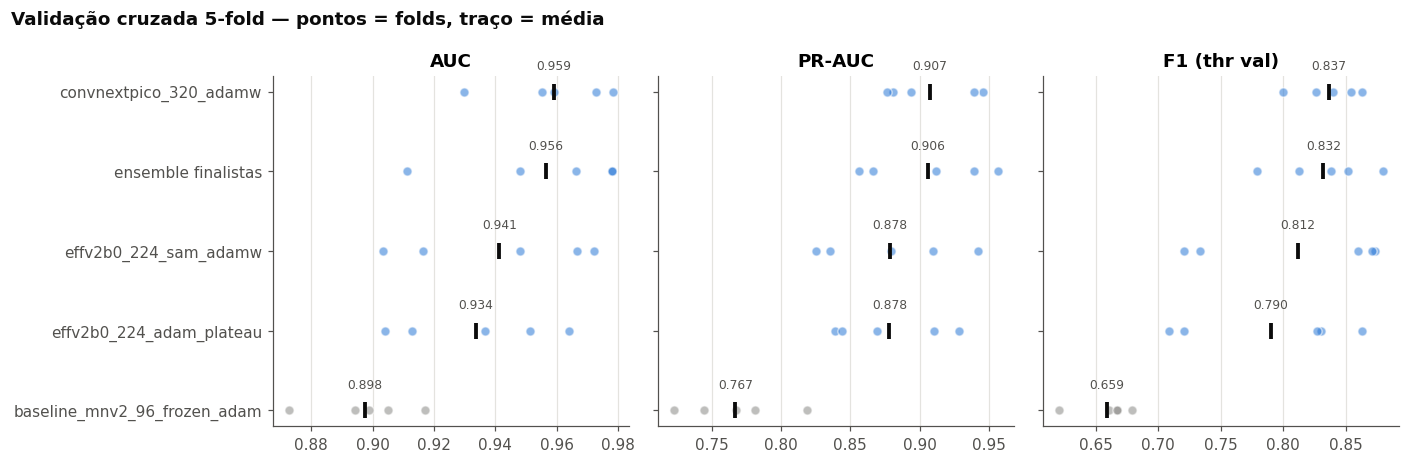

In [5]:
novos = [m for m in oof if not m.startswith("baseline") and len(oof[m]) == 5]
ens = A.oof_ensemble(oof, novos); ens["modelo"] = "ensemble(" + "+".join(novos) + ")"
display(ens.drop(columns="modelo").agg(["mean","std"]).T.round(3))
ens_plot = ens.assign(modelo="ensemble finalistas")
A.cv_boxplot(por_fold, extra=ens_plot, arquivo="cv_folds.png");

## Com TTA (flip horizontal)

In [6]:
pf_tta, resumo_tta, oof_tta = A.cv_resumo("cv_", tta=True)
resumo_tta.drop(columns="AUC_mean")

,AUC,PR-AUC,F1 (thr val),Precisão (thr val),Recall (thr val),"Prec. c/ recall≥0,85 (thr val)",n_folds
modelo,,,,,,,
convnextpico_320_adamw,0.965 ± 0.010,0.912 ± 0.029,0.846 ± 0.031,0.860 ± 0.028,0.835 ± 0.058,0.877 ± 0.048,5
effv2b0_224_sam_adamw,0.939 ± 0.032,0.881 ± 0.050,0.810 ± 0.084,0.864 ± 0.065,0.769 ± 0.121,0.798 ± 0.106,5
effv2b0_224_adam_plateau,0.936 ± 0.027,0.880 ± 0.042,0.780 ± 0.068,0.817 ± 0.069,0.757 ± 0.119,0.801 ± 0.087,5
baseline_mnv2_96_frozen_adam,0.903 ± 0.014,0.770 ± 0.036,0.675 ± 0.019,0.646 ± 0.063,0.718 ± 0.069,0.588 ± 0.054,5


## Comparação pareada com o baseline (mesmos folds)

In [7]:
import numpy as np
piv = por_fold.pivot(index="fold", columns="modelo", values="AUC")
dif = piv.drop(columns="baseline_mnv2_96_frozen_adam").sub(piv["baseline_mnv2_96_frozen_adam"], axis=0)
print("Ganho de AUC sobre o baseline, por fold:"); display(dif.round(3))
print("Folds em que o modelo vence o baseline:", (dif > 0).sum().to_dict())
pivp = por_fold.pivot(index="fold", columns="modelo", values="PR-AUC")
difp = pivp.drop(columns="baseline_mnv2_96_frozen_adam").sub(pivp["baseline_mnv2_96_frozen_adam"], axis=0)
print("Ganho de PR-AUC sobre o baseline, por fold:"); display(difp.round(3))

Ganho de AUC sobre o baseline, por fold:


modelo,convnextpico_320_adamw,effv2b0_224_adam_plateau,effv2b0_224_sam_adamw
fold,,,
0,0.080,0.065,0.068
1,0.057,0.032,0.031
2,0.042,-0.004,0.031
3,0.068,0.046,0.067
4,0.061,0.042,0.022


Folds em que o modelo vence o baseline: {'convnextpico_320_adamw': 5, 'effv2b0_224_adam_plateau': 4, 'effv2b0_224_sam_adamw': 5}
Ganho de PR-AUC sobre o baseline, por fold:


modelo,convnextpico_320_adamw,effv2b0_224_adam_plateau,effv2b0_224_sam_adamw
fold,,,
0,0.223,0.188,0.187
1,0.099,0.057,0.054
2,0.126,0.102,0.112
3,0.121,0.110,0.124
4,0.132,0.099,0.081


## Campeão e threshold operacional

In [8]:
tab = por_fold.groupby("modelo")[["AUC","PR-AUC","F1 (thr val)"]].mean()
tab.loc["ensemble finalistas"] = ens[["AUC","PR-AUC","F1 (thr val)"]].mean()
tab = tab.sort_values("PR-AUC", ascending=False)
print(tab.round(3))

                                AUC  PR-AUC  F1 (thr val)
modelo                                                   
convnextpico_320_adamw        0.959   0.907         0.837
ensemble finalistas           0.956   0.906         0.832
effv2b0_224_sam_adamw         0.941   0.878         0.812
effv2b0_224_adam_plateau      0.934   0.878         0.790
baseline_mnv2_96_frozen_adam  0.898   0.767         0.659


In [9]:
cfg_campeao = json.load(open("modelos/campeao_config.json"))
print(json.dumps({k: v for k, v in cfg_campeao.items() if k != "cfg"}, indent=1, ensure_ascii=False))

{
 "modelo": "convnextpico_320_adamw",
 "descricao": "ConvNeXt-Pico (ImageNet) 320px, fine-tuning completo, AdamW+cosine; inferência = média dos 5 modelos dos folds + TTA (flip horizontal)",
 "rotulo": "1 = imagem contém ao menos um MILCO (mine-like contact)",
 "arquivos": [
  "campeao_convnextpico_320_adamw_fold0.pt",
  "campeao_convnextpico_320_adamw_fold1.pt",
  "campeao_convnextpico_320_adamw_fold2.pt",
  "campeao_convnextpico_320_adamw_fold3.pt",
  "campeao_convnextpico_320_adamw_fold4.pt"
 ],
 "img_size": 320,
 "threshold_max_f1": 0.6321455836296082,
 "oof_no_threshold_max_f1": {
  "precisao": 0.8233082706766918,
  "recall": 0.8588235294117647,
  "f1": 0.8406909788862563
 },
 "threshold_recall_85": 0.6321455836296082,
 "oof_no_threshold_recall_85": {
  "precisao": 0.8233082706766918,
  "recall": 0.8588235294117647
 },
 "oof_auc": 0.9587570984678023,
 "oof_pr_auc": 0.896088704230776,
 "obs": "Thresholds calibrados nas 1170 predições out-of-fold (cada imagem prevista por um modelo 

## Conclusão
- **Campeão: ConvNeXt-Pico (ImageNet), 320 px, fine-tuning completo com AdamW + cosine, TTA com flip horizontal.** Em 5-fold: AUC ≈ 0,965 ± 0,010, PR-AUC ≈ 0,91, F1 ≈ 0,85 — contra AUC 0,90 / PR-AUC 0,77 / F1 0,67 do baseline (MobileNetV2 96 px congelado + Adam), vencendo o baseline em todos os folds.
- O ensemble ConvNeXt-Pico 320 + EfficientNetV2-B0 SAM empata com o ConvNeXt sozinho, custando o dobro: não compensa.
- Para produção, o arquivo `modelos/` guarda os 5 modelos dos folds (média = *bagging*) e os thresholds calibrados nas predições out-of-fold; `inferencia.py` aplica tudo em novas imagens.